<a href="https://colab.research.google.com/github/ADwiS777/Data-Visualization-Layanan-ART/blob/main/2418040DataVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Import Libraries Dan Baca Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import re

print("Google Drive berhasil dihubungkan.")

path_file = (
    "/content/drive/MyDrive/2418040_Data Mining/Data/Dataset Layanan ART.xlsx"
)

if not os.path.exists(path_file):
    raise FileNotFoundError(
        "File tidak ditemukan. Periksa kembali lokasi dan nama file."
    )

df = pd.read_excel(path_file)

print("Dataset berhasil dibaca.")
print("Jumlah baris dan kolom:", df.shape)
print("Daftar kolom:", df.columns.tolist())

display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive berhasil dihubungkan.
Dataset berhasil dibaca.
Jumlah baris dan kolom: (200, 9)
Daftar kolom: ['No', 'Nama', 'Alamat', 'No. Telepon', 'Tanggal', 'Jam/Waktu Layanan', 'Jam Kerja', 'Jenis Layanan', 'Status Layanan']


,No,Nama,Alamat,No. Telepon,Tanggal,Jam/Waktu Layanan,Jam Kerja,Jenis Layanan,Status Layanan
0,1,Nurul Hidayah,"Jl. Cempaka, Blok B No. 11",81345678899,02-01-2026,11:30,3,Memasak,Diterima
1,2,Sinta Maharani,"Jl. Mangga, Blok B No. 20",85212345678,07-01-2026,12:30,8,Paket lengkap,Ditolak
2,3,Sri Wahyuni,"Jl. Nusa Indah, Blok B No. 12",81234009988,07-01-2026,14:15,2,Bersih-bersih,Ditolak
3,4,Rudi Hartono,"Jl. Merpati, No. 22",81399887766,08-01-2026,08:30,2,Bersih-bersih,Diterima
4,5,Fajar Ramadhan,"Jl. Melati, Blok E No. 9",8123456789,08-01-2026,07:00,5,Bersih-bersih,Diterima


# 2. Persiapan Data

In [ ]:
kolom_wajib = [
    "Nama",
    "Tanggal",
    "Jam/Waktu Layanan",
    "Jam Kerja",
    "Jenis Layanan",
    "Status Layanan"
]

kolom_tidak_ada = [
    kolom for kolom in kolom_wajib
    if kolom not in df.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {kolom_tidak_ada}"
    )

df = df.copy()

for kolom in [
    "Nama",
    "Jam/Waktu Layanan",
    "Jenis Layanan",
    "Status Layanan"
]:
    df[kolom] = df[kolom].astype("string").str.strip()

# Menyesuaikan tipe data
df["Tanggal"] = pd.to_datetime(
    df["Tanggal"], dayfirst=True, errors="coerce"
)

df["Jam Kerja"] = pd.to_numeric(
    df["Jam Kerja"], errors="coerce"
)

print("Tanggal kosong:", df["Tanggal"].isna().sum())
print("Jam kerja kosong:", df["Jam Kerja"].isna().sum())
print("Status layanan:", df["Status Layanan"].value_counts(dropna=False))

Tanggal kosong: 0
Jam kerja kosong: 0
Status layanan: Status Layanan
Diterima    142
Ditolak      58
Name: count, dtype: Int64


# 3. Membuat Kolom Tarif Layanan dan Total Biaya

In [ ]:
tarif_layanan = {
    "Bersih-bersih": 18000,
    "Memasak": 23000,
    "Paket lengkap": 30000
}

df["Tarif per Jam"] = df["Jenis Layanan"].map(tarif_layanan)

# Menghitung biaya setiap transaksi
df["Total Biaya"] = (
    df["Tarif per Jam"] * df["Jam Kerja"]
)

# Memeriksa jenis layanan yang tidak cocok dengan tarif
if df["Tarif per Jam"].isna().any():
    print("PERINGATAN: Ada jenis layanan tanpa tarif yang cocok.")
    display(
        df.loc[df["Tarif per Jam"].isna(), ["Jenis Layanan"]]
        .drop_duplicates()
    )
else:
    print("Semua jenis layanan memiliki tarif.")

display(df[[
    "Nama",
    "Tanggal",
    "Jam/Waktu Layanan",
    "Jenis Layanan",
    "Jam Kerja",
    "Tarif per Jam",
    "Total Biaya",
    "Status Layanan"
]].head(10))

Semua jenis layanan memiliki tarif.


,Nama,Tanggal,Jam/Waktu Layanan,Jenis Layanan,Jam Kerja,Tarif per Jam,Total Biaya,Status Layanan
0,Nurul Hidayah,2026-01-02,11:30,Memasak,3,23000,69000,Diterima
1,Sinta Maharani,2026-01-07,12:30,Paket lengkap,8,30000,240000,Ditolak
2,Sri Wahyuni,2026-01-07,14:15,Bersih-bersih,2,18000,36000,Ditolak
3,Rudi Hartono,2026-01-08,08:30,Bersih-bersih,2,18000,36000,Diterima
4,Fajar Ramadhan,2026-01-08,07:00,Bersih-bersih,5,18000,90000,Diterima
5,Rangga Saputra,2026-01-12,12:45,Bersih-bersih,1,18000,18000,Ditolak
6,Nanda Putra,2026-01-13,08:00,Bersih-bersih,2,18000,36000,Diterima
7,Rangga Saputra,2026-01-16,14:00,Memasak,1,23000,23000,Ditolak
8,Reza Pratama,2026-01-16,12:15,Paket lengkap,3,30000,90000,Diterima
9,Dewi Lestari,2026-01-18,08:15,Paket lengkap,7,30000,210000,Ditolak


# 4. Membuat Data Agregat

In [ ]:
data = df.dropna(subset=["Tanggal"]).copy()

# Menormalkan status agar tidak terpengaruh huruf besar/kecil
status_normal = (
    data["Status Layanan"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

data["Diterima"] = status_normal.eq("diterima")
data["Bulan"] = data["Tanggal"].dt.to_period("M")

# Memilih tahun yang akan divisualisasikan
tahun_tersedia = sorted(data["Tanggal"].dt.year.dropna().unique())

if not tahun_tersedia:
    raise ValueError("Tidak ada tanggal valid untuk agregasi.")

tahun_analisis = tahun_tersedia[0]

if len(tahun_tersedia) > 1:
    print("Tahun yang tersedia:", tahun_tersedia)
    print("Grafik saat ini menggunakan tahun:", tahun_analisis)

data_tahun = data[data["Tanggal"].dt.year == tahun_analisis].copy()

semua_bulan = pd.period_range(
    start=f"{tahun_analisis}-01",
    end=f"{tahun_analisis}-12",
    freq="M"
)

# Jumlah seluruh pemesanan
jumlah_transaksi = (
    data_tahun.groupby("Bulan").size()
    .reindex(semua_bulan, fill_value=0)
)

# Jumlah nama pelanggan yang unik setiap bulan
jumlah_pelanggan = (
    data_tahun.groupby("Bulan")["Nama"].nunique()
    .reindex(semua_bulan, fill_value=0)
)

# Jumlah transaksi yang diterima
transaksi_diterima = (
    data_tahun[data_tahun["Diterima"]]
    .groupby("Bulan").size()
    .reindex(semua_bulan, fill_value=0)
)

# Pendapatan hanya dari transaksi diterima dengan biaya valid
pendapatan = (
    data_tahun.loc[
        data_tahun["Diterima"] &
        data_tahun["Total Biaya"].notna()
    ]
    .groupby("Bulan")["Total Biaya"].sum()
    .reindex(semua_bulan, fill_value=0)
)

nama_bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli", "Agustus",
    "September", "Oktober", "November", "Desember"
]

agregat_bulanan = pd.DataFrame({
    "Bulan": nama_bulan,
    "Jumlah Pelanggan Unik": jumlah_pelanggan.to_numpy(),
    "Jumlah Transaksi": jumlah_transaksi.to_numpy(),
    "Transaksi Diterima": transaksi_diterima.to_numpy(),
    "Pendapatan": pendapatan.to_numpy()
})

print("Agregat bulanan tahun", tahun_analisis)
display(agregat_bulanan)

Agregat bulanan tahun 2026


,Bulan,Jumlah Pelanggan Unik,Jumlah Transaksi,Transaksi Diterima,Pendapatan
0,Januari,14,16,7,452000
1,Februari,9,11,7,526000
2,Maret,14,15,11,1153000
3,April,14,15,11,1219000
4,Mei,12,14,11,1268000
5,Juni,8,12,7,482000
6,Juli,13,13,10,942000
7,Agustus,14,14,10,1230000
8,September,14,16,12,996000
9,Oktober,34,42,30,2971000


# 5. Grafik Pendapatan Setiap Bulan

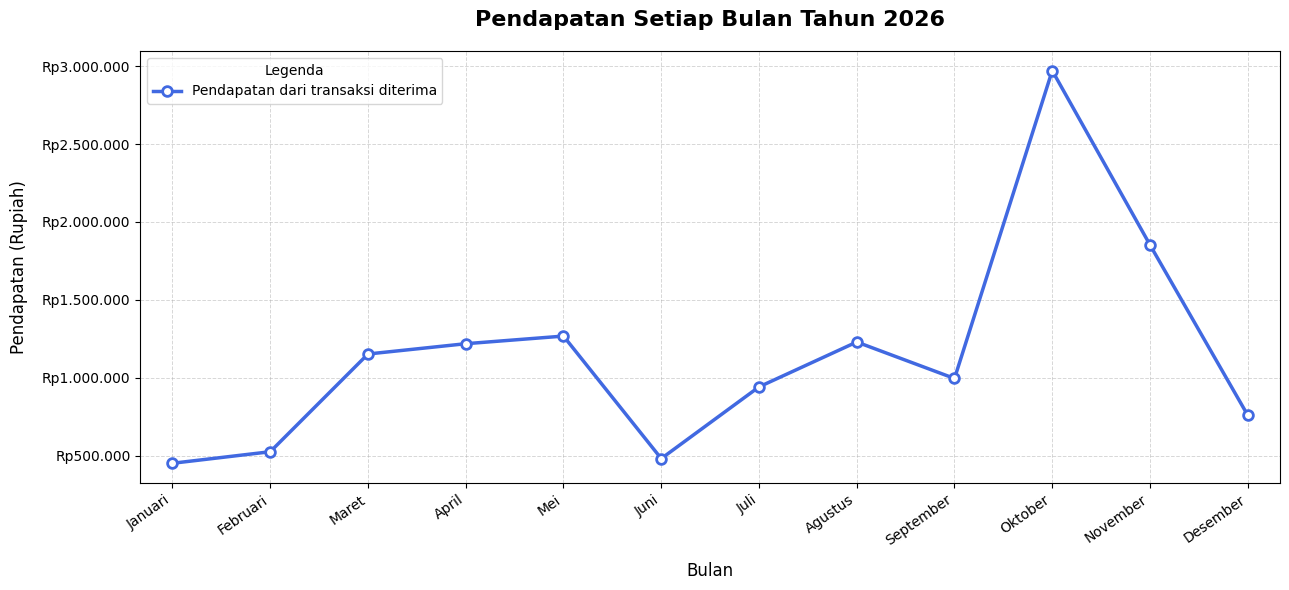

In [ ]:
fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(12)
y = agregat_bulanan["Pendapatan"]

ax.plot(
    x,
    y,
    color="royalblue",
    linewidth=2.5,
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgewidth=2,
    label="Pendapatan dari transaksi diterima"
)

ax.set_title(
    f"Pendapatan Setiap Bulan Tahun {tahun_analisis}",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Bulan", fontsize=12, labelpad=10)
ax.set_ylabel("Pendapatan (Rupiah)", fontsize=12, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(nama_bulan, rotation=35, ha="right")

ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda nilai, posisi: f"Rp{nilai:,.0f}".replace(",", ".")
    )
)

ax.grid(
    True,
    axis="both",
    linestyle="--",
    linewidth=0.7,
    alpha=0.5
)

ax.legend(loc="best", frameon=True, title="Legenda")
ax.margins(x=0.03)
fig.tight_layout()
plt.show()

# 6. Grafik Transaksi Pelanggan

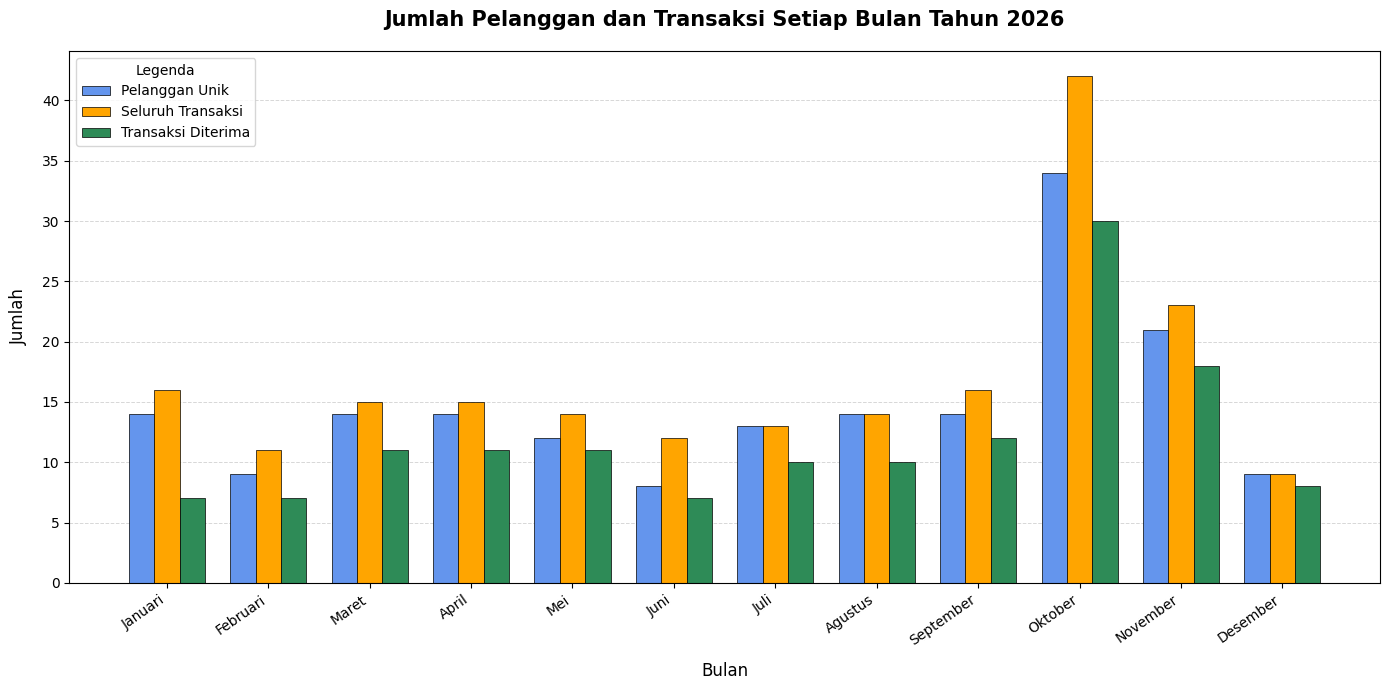

In [ ]:
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(agregat_bulanan))
lebar = 0.25

ax.bar(
    x - lebar,
    agregat_bulanan["Jumlah Pelanggan Unik"],
    width=lebar,
    label="Pelanggan Unik",
    color="cornflowerblue",
    edgecolor="black",
    linewidth=0.5
)

ax.bar(
    x,
    agregat_bulanan["Jumlah Transaksi"],
    width=lebar,
    label="Seluruh Transaksi",
    color="orange",
    edgecolor="black",
    linewidth=0.5
)

ax.bar(
    x + lebar,
    agregat_bulanan["Transaksi Diterima"],
    width=lebar,
    label="Transaksi Diterima",
    color="seagreen",
    edgecolor="black",
    linewidth=0.5
)

ax.set_title(
    f"Jumlah Pelanggan dan Transaksi Setiap Bulan Tahun {tahun_analisis}",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Bulan", fontsize=12, labelpad=10)
ax.set_ylabel("Jumlah", fontsize=12, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(nama_bulan, rotation=35, ha="right")

ax.grid(
    True,
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.5
)

ax.set_axisbelow(True)
ax.legend(loc="upper left", frameon=True, title="Legenda")
fig.tight_layout()
plt.show()

# 7. Menentukan Waktu Pemesanan Paling Ramai

In [ ]:
def ekstrak_jam_mulai(nilai):
    if pd.isna(nilai):
        return np.nan

    teks = str(nilai).strip()

    # Mencari format HH:MM atau HH.MM
    cocok = re.search(
        r"(?<!\d)([01]?\d|2[0-3])[:.]([0-5]\d)(?!\d)",
        teks
    )

    if cocok:
        jam = int(cocok.group(1))
        menit = int(cocok.group(2))

        # Kelompokkan berdasarkan jam mulai
        return jam

    cocok_jam = re.fullmatch(r"\s*([01]?\d|2[0-3])\s*", teks)

    if cocok_jam:
        return int(cocok_jam.group(1))

    return np.nan


data_waktu = data_tahun.copy()

data_waktu["Jam Mulai"] = (
    data_waktu["Jam/Waktu Layanan"]
    .apply(ekstrak_jam_mulai)
)

print("Jumlah waktu yang berhasil dibaca:",
      data_waktu["Jam Mulai"].notna().sum())

print("Jumlah waktu yang tidak dapat dibaca:",
      data_waktu["Jam Mulai"].isna().sum())

# Memeriksa format yang tidak berhasil diekstrak
display(
    data_waktu.loc[
        data_waktu["Jam Mulai"].isna(),
        ["Jam/Waktu Layanan"]
    ].drop_duplicates().head(20)
)

Jumlah waktu yang berhasil dibaca: 200
Jumlah waktu yang tidak dapat dibaca: 0


,Jam/Waktu Layanan


# 8. Grafik Waktu Layanan Paling Ramai

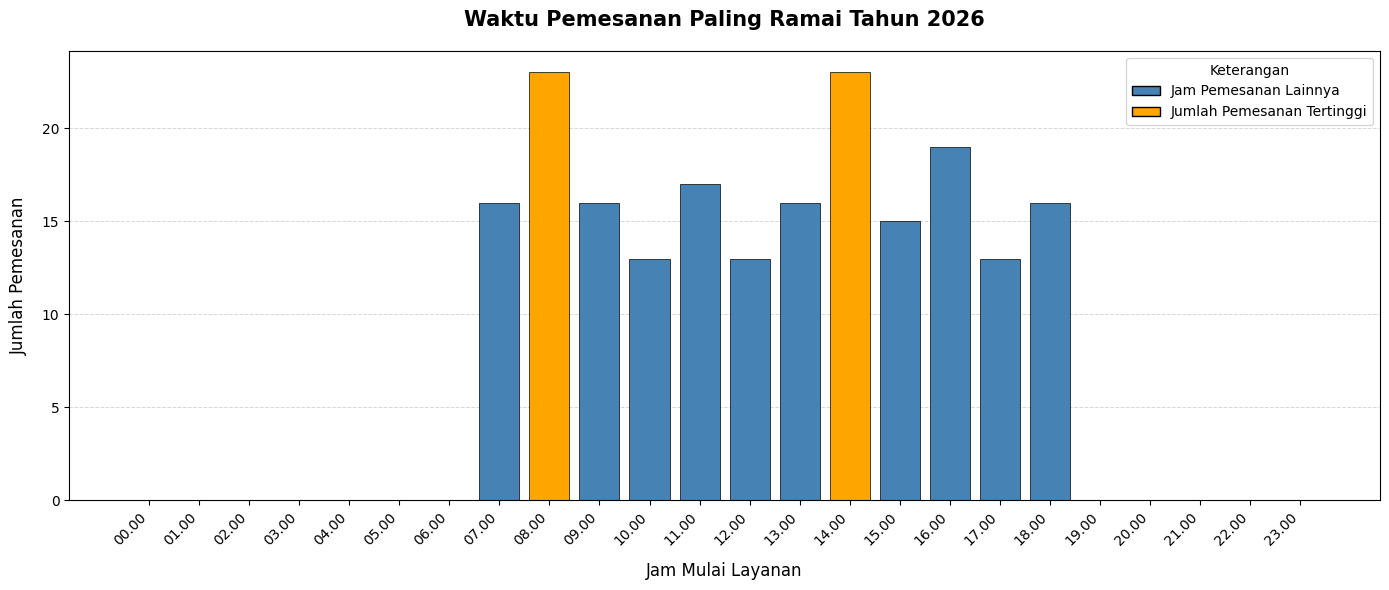

Jumlah pemesanan tertinggi: 23
Jam paling ramai: 08.00, 14.00


In [ ]:
jam_valid = data_waktu.dropna(subset=["Jam Mulai"]).copy()
jam_valid["Jam Mulai"] = jam_valid["Jam Mulai"].astype(int)

# Menghitung pemesanan berdasarkan jam mulai
agregat_jam = (
    jam_valid.groupby("Jam Mulai")
    .size()
    .reindex(range(24), fill_value=0)
)

label_jam = [f"{jam:02d}.00" for jam in range(24)]

if agregat_jam.sum() == 0:
    print("Tidak ada data waktu yang dapat digunakan untuk grafik.")
else:
    jam_tertinggi = agregat_jam.max()
    jam_teramai = agregat_jam[
        agregat_jam == jam_tertinggi
    ].index.tolist()

    warna_batang = [
        "orange" if jam in jam_teramai else "steelblue"
        for jam in range(24)
    ]

    fig, ax = plt.subplots(figsize=(14, 6))

    ax.bar(
        range(24),
        agregat_jam.values,
        color=warna_batang,
        edgecolor="black",
        linewidth=0.5
    )

    ax.set_title(
        f"Waktu Pemesanan Paling Ramai Tahun {tahun_analisis}",
        fontsize=15,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel("Jam Mulai Layanan", fontsize=12, labelpad=10)
    ax.set_ylabel("Jumlah Pemesanan", fontsize=12, labelpad=10)

    ax.set_xticks(range(24))
    ax.set_xticklabels(label_jam, rotation=45, ha="right")

    ax.grid(
        True,
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.5
    )

    ax.set_axisbelow(True)

    from matplotlib.patches import Patch

    legenda = [
        Patch(
            facecolor="steelblue",
            edgecolor="black",
            label="Jam Pemesanan Lainnya"
        ),
        Patch(
            facecolor="orange",
            edgecolor="black",
            label="Jumlah Pemesanan Tertinggi"
        )
    ]

    ax.legend(
        handles=legenda,
        loc="upper right",
        frameon=True,
        title="Keterangan"
    )

    fig.tight_layout()
    plt.show()

    print("Jumlah pemesanan tertinggi:", jam_tertinggi)
    print(
        "Jam paling ramai:",
        ", ".join(f"{jam:02d}.00" for jam in jam_teramai)
    )


# 9. Interpretasi Hasil

In [ ]:
# Pendapatan tertinggi dan terendah
idx_pendapatan_max = agregat_bulanan["Pendapatan"].idxmax()
idx_pendapatan_min = agregat_bulanan["Pendapatan"].idxmin()

bulan_pendapatan_max = agregat_bulanan.loc[
    idx_pendapatan_max, "Bulan"
]
nilai_pendapatan_max = agregat_bulanan.loc[
    idx_pendapatan_max, "Pendapatan"
]

bulan_pendapatan_min = agregat_bulanan.loc[
    idx_pendapatan_min, "Bulan"
]
nilai_pendapatan_min = agregat_bulanan.loc[
    idx_pendapatan_min, "Pendapatan"
]

# Transaksi terbanyak
idx_transaksi_max = agregat_bulanan["Jumlah Transaksi"].idxmax()
bulan_transaksi_max = agregat_bulanan.loc[
    idx_transaksi_max, "Bulan"
]
nilai_transaksi_max = agregat_bulanan.loc[
    idx_transaksi_max, "Jumlah Transaksi"
]

# Transaksi diterima terbanyak
idx_diterima_max = agregat_bulanan["Transaksi Diterima"].idxmax()
bulan_diterima_max = agregat_bulanan.loc[
    idx_diterima_max, "Bulan"
]
nilai_diterima_max = agregat_bulanan.loc[
    idx_diterima_max, "Transaksi Diterima"
]

# Pelanggan unik terbanyak
idx_pelanggan_max = agregat_bulanan[
    "Jumlah Pelanggan Unik"
].idxmax()

bulan_pelanggan_max = agregat_bulanan.loc[
    idx_pelanggan_max, "Bulan"
]
nilai_pelanggan_max = agregat_bulanan.loc[
    idx_pelanggan_max, "Jumlah Pelanggan Unik"
]

print("INTERPRETASI GRAFIK")
print("=" * 50)

print(
    f"1. Pendapatan tertinggi terjadi pada {bulan_pendapatan_max}, "
    f"sebesar Rp{nilai_pendapatan_max:,.0f}."
    .replace(",", ".")
)

print(
    f"2. Pendapatan terendah terjadi pada {bulan_pendapatan_min}, "
    f"sebesar Rp{nilai_pendapatan_min:,.0f}."
    .replace(",", ".")
)

print(
    f"3. Jumlah transaksi terbanyak terjadi pada {bulan_transaksi_max}, "
    f"sebanyak {nilai_transaksi_max} transaksi."
)

print(
    f"4. Transaksi diterima terbanyak terjadi pada {bulan_diterima_max}, "
    f"sebanyak {nilai_diterima_max} transaksi."
)

print(
    f"5. Pelanggan unik terbanyak terjadi pada {bulan_pelanggan_max}, "
    f"sebanyak {nilai_pelanggan_max} pelanggan."
)

if agregat_jam.sum() > 0:
    print(
        "6. Jam mulai layanan paling ramai: "
        + ", ".join(f"{jam:02d}.00" for jam in jam_teramai)
        + f", sebanyak {jam_tertinggi} pemesanan."
    )
else:
    print(
        "6. Waktu paling ramai belum dapat ditentukan karena "
        "tidak ada waktu valid yang berhasil dibaca."
    )

INTERPRETASI GRAFIK
1. Pendapatan tertinggi terjadi pada Oktober. sebesar Rp2.971.000.
2. Pendapatan terendah terjadi pada Januari. sebesar Rp452.000.
3. Jumlah transaksi terbanyak terjadi pada Oktober, sebanyak 42 transaksi.
4. Transaksi diterima terbanyak terjadi pada Oktober, sebanyak 30 transaksi.
5. Pelanggan unik terbanyak terjadi pada Oktober, sebanyak 34 pelanggan.
6. Jam mulai layanan paling ramai: 08.00, 14.00, sebanyak 23 pemesanan.


# 10. Menyimpan Hasil

In [ ]:
folder_output = "/content/drive/MyDrive/2418040_Data Mining/Data"
os.makedirs(folder_output, exist_ok=True)

path_output = os.path.join(
    folder_output,
    "Hasil_Analisis_Layanan_ART.xlsx"
)

with pd.ExcelWriter(path_output, engine="openpyxl") as writer:
    df.to_excel(
        writer,
        sheet_name="Data dengan Total Biaya",
        index=False
    )

    agregat_bulanan.to_excel(
        writer,
        sheet_name="Agregat Bulanan",
        index=False
    )

    agregat_jam.rename(
        "Jumlah Pemesanan"
    ).rename_axis(
        "Jam Mulai"
    ).reset_index().to_excel(
        writer,
        sheet_name="Agregat Waktu",
        index=False
    )

print("Hasil analisis berhasil disimpan di:")
print(path_output)

Hasil analisis berhasil disimpan di:
/content/drive/MyDrive/2418040_Data Mining/Data/Hasil_Analisis_Layanan_ART.xlsx


# Kesimpulan

Proyek ini mengolah dataset layanan ART menjadi informasi yang lebih mudah dipahami melalui penghitungan tarif dan total biaya, agregasi bulanan, serta tiga visualisasi. Grafik garis digunakan untuk menganalisis pendapatan, grafik batang berkelompok untuk membandingkan pelanggan dan transaksi, dan grafik batang berdasarkan jam untuk mengidentifikasi waktu mulai layanan yang paling ramai. Hasil analisis dapat membantu mengevaluasi pendapatan, volume pemesanan, dan distribusi waktu layanan.